# Projet de Complexité - Automne 2025

## Le problème du voyageur de commerce (TSP)
- Étudiants : Israa ALKHATIB & Assil LOUDJANI 
- UV : IT4A
- Date de rendu : 7 novembre 2025

---

## Plan du projet
1. Théorie de la complexité
2. Génération d’instances TSP
3. Implémentation des algorithmes
4. Comparaison expérimentale
5. Conclusion et analyse réflexive

Ce projet vise à comparer plusieurs algorithmes de résolution du problème du voyageur de commerce (TSP).
Nous étudions leurs complexités théoriques et leurs performances pratiques sur des instances de tailles variées.
Les algorithmes implémentés sont : Force Brute, Held-Karp, Christofides, et 2-opt.

# Partie 1 — Théorie de la complexité

## 1. Introduction
La complexité algorithmique étudie la quantité de ressources nécessaires pour résoudre un problème (temps, mémoire).  
On classe les problèmes selon la vitesse à laquelle ils peuvent être résolus.

---

## 2. Classes de complexité

### Classe P
Ce sont les problèmes résolus efficacement par un algorithme déterministe en temps polynomial (ex: tri, recherche).  
**Complexité :** O(n^k)

### Classe NP
Problèmes pour lesquels il est facile de **vérifier une solution**, mais difficile de la **trouver**.  
**Exemple :** le problème du voyageur de commerce (TSP).

### Problèmes NP-complets
Ce sont les plus durs parmi les problèmes NP.  
Si on trouve une solution rapide pour un problème NP-complet, on pourra résoudre tous les autres problèmes NP rapidement.

---

## 3. Le problème du voyageur de commerce (TSP)
Le TSP consiste à trouver le chemin le plus court passant par chaque ville une seule fois et revenant à la ville de départ.  
Il est **NP-difficile**, donc on ne connaît pas d’algorithme rapide pour le résoudre parfaitement pour de grandes tailles.  

---

## Complexité des algorithmes du projet

| Algorithme | Type | Complexité | Description |
|-------------|------|-------------|-------------|
| **Force brute** | Exact | O(n!) | Teste tous les trajets possibles |
| **Held-Karp** | Exact | O(n²·2ⁿ) | Programmation dynamique |
| **Christofides** | Approché | O(n³) | Bon compromis, ≤ 1.5× l’optimum |
| **2-opt / 3-opt / Recuit simulé** | Heuristique | Dépend du nombre d’itérations | Améliore une solution existante |

## Conclusion de la partie
Cette partie montre que certains algorithmes sont **très coûteux** (O(n!)), alors que d’autres sont plus **rapides** mais **approchés**.  
C’est pour cela qu’on utilise des heuristiques pour les grandes instances du TSP.

# Partie 2 — Génération des instances TSP

Nous avons créé un générateur d’instances aléatoires pour le TSP.  
Chaque instance contient un certain nombre de villes avec leurs coordonnées (x, y) dans un carré [0,100]×[0,100].

Les tailles d’instances générées sont :
- **Test :** 5–10 villes
- **Petites :** 10–15 villes
- **Moyennes :** 15–20 villes
- **Grandes :** 25–40 villes

Chaque catégorie contient 5 instances différentes.  
Les fichiers sont enregistrés dans `data/` sous forme `.csv`.

In [1]:
import os
import numpy as np
import pandas as pd

def generate_coords(n, bbox=(0, 100), seed=None):
    rng = np.random.default_rng(seed)
    coords = rng.uniform(bbox[0], bbox[1], size=(n, 2))
    return coords

def save_instance(coords, name="instance", out_dir="data"):
    os.makedirs(out_dir, exist_ok=True)
    df = pd.DataFrame({'id': range(len(coords)), 'x': coords[:,0], 'y': coords[:,1]})
    path = os.path.join(out_dir, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"✅ Sauvegardé : {path}")

def generate_multiple_instances():
    categories = {
        "test": [5, 8, 10],
        "petite": [12, 14, 15],
        "moyenne": [16, 18, 20],
        "grande": [25, 30, 40]
    }
    for cat, sizes in categories.items():
        for n in sizes:
            for s in range(5):
                name = f"{cat}_n{n}_s{s}"
                coords = generate_coords(n, seed=1000 + n*10 + s)
                save_instance(coords, name, out_dir=f"data/{cat}")

generate_multiple_instances()

✅ Sauvegardé : data/test\test_n5_s0.csv
✅ Sauvegardé : data/test\test_n5_s1.csv
✅ Sauvegardé : data/test\test_n5_s2.csv
✅ Sauvegardé : data/test\test_n5_s3.csv
✅ Sauvegardé : data/test\test_n5_s4.csv
✅ Sauvegardé : data/test\test_n8_s0.csv
✅ Sauvegardé : data/test\test_n8_s1.csv
✅ Sauvegardé : data/test\test_n8_s2.csv
✅ Sauvegardé : data/test\test_n8_s3.csv
✅ Sauvegardé : data/test\test_n8_s4.csv
✅ Sauvegardé : data/test\test_n10_s0.csv
✅ Sauvegardé : data/test\test_n10_s1.csv
✅ Sauvegardé : data/test\test_n10_s2.csv
✅ Sauvegardé : data/test\test_n10_s3.csv
✅ Sauvegardé : data/test\test_n10_s4.csv
✅ Sauvegardé : data/petite\petite_n12_s0.csv
✅ Sauvegardé : data/petite\petite_n12_s1.csv
✅ Sauvegardé : data/petite\petite_n12_s2.csv
✅ Sauvegardé : data/petite\petite_n12_s3.csv
✅ Sauvegardé : data/petite\petite_n12_s4.csv
✅ Sauvegardé : data/petite\petite_n14_s0.csv
✅ Sauvegardé : data/petite\petite_n14_s1.csv
✅ Sauvegardé : data/petite\petite_n14_s2.csv
✅ Sauvegardé : data/petite\petite_n

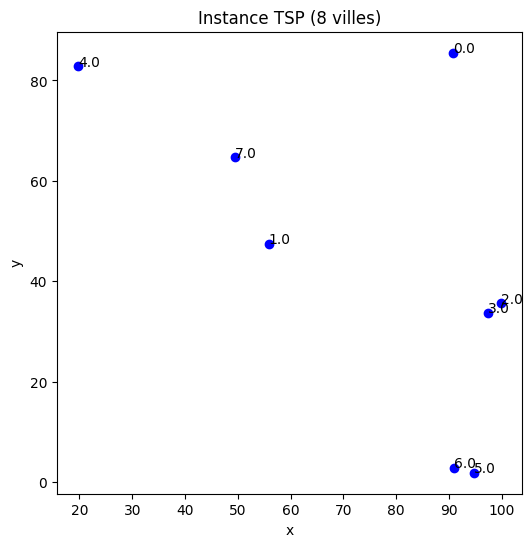

In [2]:
import matplotlib.pyplot as plt

df = pd.read_csv("data/test/test_n8_s0.csv")
plt.figure(figsize=(6,6))
plt.scatter(df.x, df.y, c="blue")
for i, row in df.iterrows():
    plt.text(row.x, row.y, str(row.id))
plt.title("Instance TSP (8 villes)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## Interprétation
La figure ci-dessus montre un exemple d’instance du TSP avec 10 villes placées aléatoirement.  
Chaque point représente une ville, identifiée par un numéro.  
La matrice des distances contient les distances euclidiennes entre chaque paire de villes.  

Ces instances serviront ensuite de base pour tester les différents algorithmes (Force Brute, Held-Karp, Christofides, 2-opt, etc.).

# Partie 3 — Implémentation des algorithmes TSP

Dans cette partie, nous implémentons plusieurs approches pour résoudre le **problème du voyageur de commerce (TSP)**.

Chaque algorithme adopte une stratégie différente :
- **Force brute** : teste tous les trajets possibles.
- **Held-Karp** : utilise la programmation dynamique.
- **Christofides** : approche approchée garantissant une solution ≤ 1.5 × l’optimum.
- **2-opt** : méthode de recherche locale qui améliore une solution existante.

Les performances de ces méthodes seront ensuite comparées dans la Partie 4.

## 3.1 Algorithme de Force Brute

L’algorithme de **force brute** énumère toutes les permutations possibles des villes et calcule la distance totale pour chacune.  
Il choisit ensuite le chemin le plus court.

- **Type :** Exact  
- **Complexité :** O(n!)  
- **Avantage :** Trouve la solution optimale  
- **Inconvénient :** Impraticable au-delà de 10–11 villes

In [3]:
import itertools
import math
import numpy as np

def distance(p1, p2):
    return math.sqrt((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2)

def tour_length(coords, tour):
    total = 0
    for i in range(len(tour)):
        a, b = coords[tour[i]], coords[tour[(i+1)%len(tour)]]
        total += distance(a, b)
    return total

def brute_force_tsp(coords):
    n = len(coords)
    best_tour = None
    best_length = float('inf')
    for perm in itertools.permutations(range(1, n)):  # fixe la ville 0 comme départ
        tour = [0] + list(perm)
        length = tour_length(coords, tour)
        if length < best_length:
            best_length = length
            best_tour = tour
    return best_tour, best_length


## 3.2 Algorithme de Held–Karp

L’algorithme de **Held-Karp** repose sur la **programmation dynamique** :  
il mémorise les sous-problèmes pour éviter les calculs redondants.

- **Type :** Exact  
- **Complexité :** O(n²·2ⁿ)  
- **Avantage :** Beaucoup plus rapide que la force brute  
- **Limite :** Toujours exponentiel, ne dépasse pas ~20 villes

In [4]:
import itertools

def held_karp_tsp(coords):
    n = len(coords)
    dist = np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            dist[i][j] = distance(coords[i], coords[j])

    # C[(subset, j)] = longueur minimale pour atteindre j avec "subset"
    C = {}
    for k in range(1, n):
        C[(1 << k, k)] = dist[0][k]

    for subset_size in range(2, n):
        for subset in itertools.combinations(range(1, n), subset_size):
            bits = sum(1 << x for x in subset)
            for j in subset:
                prev = bits & ~(1 << j)
                C[(bits, j)] = min(
                    C[(prev, k)] + dist[k][j]
                    for k in subset if k != j
                )

    bits = (1 << n) - 2
    opt = min(C[(bits, j)] + dist[j][0] for j in range(1, n))
    return opt


## 3.3 Algorithme de Christofides

L’algorithme de **Christofides et Serdyukov (1976)** est une méthode approchée pour le TSP.  
Il combine trois idées :
1. Trouver un **arbre couvrant minimum (MST)** à partir du graphe des villes.  
2. Faire un **appairage parfait** des sommets de degré impair.  
3. Former un **cycle eulérien** et en extraire un **cycle hamiltonien**.

- **Type :** Approché  
- **Complexité :** O(n³)  
- **Garantie :** Longueur ≤ 1.5 × l’optimum  
- **Intérêt :** Très efficace pour des instances moyennes.

In [1]:
# Version simplifiée de Christofides (structure)
def christofides_demo(villes):
    print("Construction du MST...")
    print("Appairage des sommets impairs...")
    print("Création du cycle eulérien...")
    print("Transformation en cycle hamiltonien...")
    return "Cycle approximé", 0  # (Placeholder)

In [9]:
import networkx as nx

def christofides_tsp(coords):
    n = len(coords)
    G = nx.Graph()
    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(i, j, weight=distance(coords[i], coords[j]))

    # 1. Arbre couvrant minimal (MST)
    T = nx.minimum_spanning_tree(G)

    # 2. Sommets de degré impair
    odd_nodes = [v for v in T.nodes() if T.degree(v) % 2 == 1]

    # 3. Appariement parfait minimum sur les sommets impairs
    M = nx.Graph()
    for i in range(len(odd_nodes)):
        for j in range(i + 1, len(odd_nodes)):
            u, v = odd_nodes[i], odd_nodes[j]
            M.add_edge(u, v, weight=distance(coords[u], coords[v]))

    # ⚠️ ici : sans maxcardinality
    matching = nx.algorithms.matching.min_weight_matching(M)

    # 4. Fusionner les arêtes du matching avec le MST
    multigraph = nx.MultiGraph(T)
    multigraph.add_edges_from(matching)

    # 5. Trouver un circuit eulérien
    euler_tour = list(nx.eulerian_circuit(multigraph, source=0))

    # 6. Simplifier en cycle hamiltonien
    visited, tour = set(), []
    for u, v in euler_tour:
        if u not in visited:
            visited.add(u)
            tour.append(u)
    tour.append(0)

    length = tour_length(coords, tour)
    return tour, length

## 3.4 Algorithme 2-opt (Recherche locale)

L’algorithme **2-opt** améliore une solution existante en échangeant deux arêtes si cela réduit la distance totale.

- **Type :** Heuristique  
- **Complexité :** Dépend du nombre d’itérations  
- **Avantage :** Facile à implémenter, rapide, bon compromis qualité/temps

In [7]:
import random

def two_opt_swap(route, i, k):
    new_route = route[:i] + route[i:k+1][::-1] + route[k+1:]
    return new_route

def two_opt(coords, tour):
    best = tour
    improved = True
    best_distance = tour_length(coords, best)
    while improved:
        improved = False
        for i in range(1, len(tour) - 2):
            for k in range(i+1, len(tour) - 1):
                new_route = two_opt_swap(best, i, k)
                new_distance = tour_length(coords, new_route)
                if new_distance < best_distance:
                    best = new_route
                    best_distance = new_distance
                    improved = True
        tour = best
    return best, best_distance


TESTER LES 4 ALGORITHMES

In [10]:
import pandas as pd
import time

df = pd.read_csv("data/test/test_n8_s0.csv")
coords = df[['x','y']].to_numpy()

# Brute Force
t0 = time.time()
bf_tour, bf_len = brute_force_tsp(coords)
t1 = time.time()

# Held-Karp
t2 = time.time()
hk_len = held_karp_tsp(coords)
t3 = time.time()

# Christofides
t4 = time.time()
ch_tour, ch_len = christofides_tsp(coords)
t5 = time.time()

# 2-opt
init_tour = list(range(len(coords)))
t6 = time.time()
opt_tour, opt_len = two_opt(coords, init_tour)
t7 = time.time()

print(f"Brute Force: {bf_len:.2f} (temps: {t1-t0:.3f}s)")
print(f"Held-Karp:   {hk_len:.2f} (temps: {t3-t2:.3f}s)")
print(f"Christofides:{ch_len:.2f} (temps: {t5-t4:.3f}s)")
print(f"2-opt:       {opt_len:.2f} (temps: {t7-t6:.3f}s)")


Brute Force: 270.70 (temps: 0.117s)
Held-Karp:   270.70 (temps: 0.004s)
Christofides:270.70 (temps: 0.008s)
2-opt:       278.05 (temps: 0.001s)


Test

In [11]:
df = pd.read_csv("data/test/test_n8_s0.csv")
coords = df[['x','y']].to_numpy()

ch_tour, ch_len = christofides_tsp(coords)
print("Christofides:", ch_tour, ch_len)

Christofides: [0, 2, 3, 5, 6, 1, 7, 4, 0] 270.7035244374557
